# Results and Graphs

This notebook summarizes the main experimental results of the quantized
neural-network accelerator project. The figures compare FP32 and INT8
accuracy, modeled latency, throughput scaling, and memory-bandwidth effects.

## 1. FP32 vs INT8 Accuracy

This figure compares MNIST test accuracy before and after INT8
post-training quantization. The goal is to determine whether reducing
numerical precision affects classification accuracy.

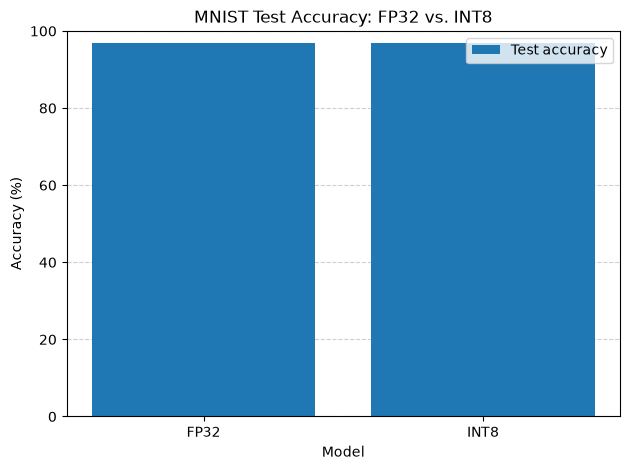

In [2]:
import matplotlib.pyplot as plt

models = ["FP32", "INT8"]
accuracy = [96.96, 96.99]

fig, ax = plt.subplots()
ax.bar(models, accuracy, label="Test accuracy")
ax.set_title("MNIST Test Accuracy: FP32 vs. INT8")
ax.set_xlabel("Model")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.set_axisbelow(True)
ax.legend()
fig.tight_layout()
plt.show()

### Observation
The FP32 model achieved 96.96% accuracy, while the INT8 model achieved 96.99% accuracy. The difference of only 0.03 percentage points shows that INT8 quantization preserved essentially the same classification accuracy as the original FP32 model. The slight increase should not be interpreted as INT8 being inherently more accurate because only 7 out of 10,000 predictions differed between the two models.

## 2. FP32 vs INT8 Modeled Latency

This figure compares the modeled accelerator latency for FP32 and INT8
inference using the baseline 8-lane accelerator configuration.

The latency values are produced by the accelerator simulator and are
not physical hardware measurements.

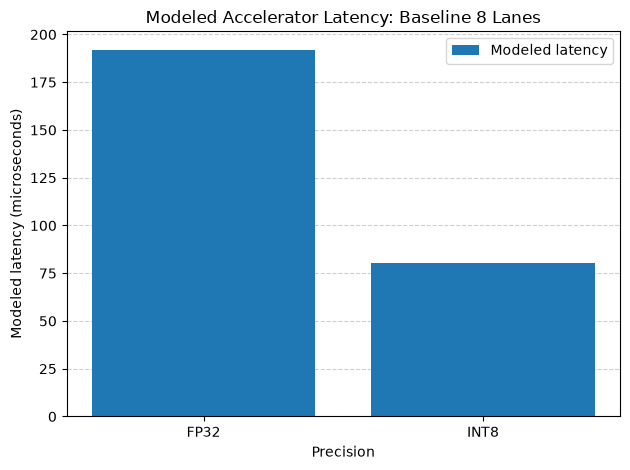

In [3]:
import matplotlib.pyplot as plt

precisions = ["FP32", "INT8"]
latency_us = [192.04, 80.25]

fig, ax = plt.subplots()
ax.bar(precisions, latency_us, label="Modeled latency")
ax.set_title("Modeled Accelerator Latency: Baseline 8 Lanes")
ax.set_xlabel("Precision")
ax.set_ylabel("Modeled latency (microseconds)")
ax.grid(axis="y", linestyle="--", alpha=0.6)
ax.set_axisbelow(True)
ax.legend()
fig.tight_layout()
plt.show()

### Observation
Using the baseline 8-lane accelerator configuration, modeled latency decreased from 192.04 µs for FP32 to 80.25 µs for INT8. This corresponds to approximately a 2.39× modeled speedup. The result shows that lower-precision computation can significantly reduce modeled inference latency while maintaining nearly identical model accuracy.

## 3. Throughput vs Accelerator Lanes

This experiment evaluates how increasing the number of parallel
accelerator lanes affects FP32 and INT8 modeled throughput.

The tested configurations use 4, 8, 16, and 32 lanes while keeping
the other architectural parameters unchanged.

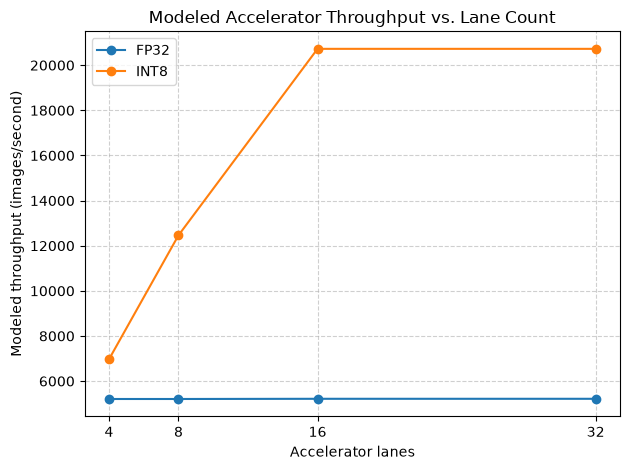

In [4]:
import matplotlib.pyplot as plt

lanes = [4, 8, 16, 32]
fp32_throughput = [5207.25, 5207.25, 5215.94, 5215.94]
int8_throughput = [6963.30, 12461.06, 20725.39, 20725.39]

fig, ax = plt.subplots()
ax.plot(lanes, fp32_throughput, marker="o", label="FP32")
ax.plot(lanes, int8_throughput, marker="o", label="INT8")
ax.set_title("Modeled Accelerator Throughput vs. Lane Count")
ax.set_xlabel("Accelerator lanes")
ax.set_ylabel("Modeled throughput (images/second)")
ax.set_xticks(lanes)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend()
fig.tight_layout()
plt.show()

### Observation

FP32 throughput remains almost unchanged as the accelerator increases from 4 to 32 lanes, staying near 5,200 images per second. In contrast, INT8 throughput increases from approximately 6,963 images/s with 4 lanes to 20,725 images/s with 16 lanes.

However, increasing from 16 to 32 lanes produces no additional improvement. This indicates diminishing returns from additional compute parallelism and suggests that another architectural resource becomes the performance bottleneck.

## 4. INT8 Throughput vs Memory Bandwidth

This experiment evaluates how external memory bandwidth affects INT8
accelerator throughput using the 32-lane configuration.

The purpose is to determine whether memory bandwidth limits performance
when additional compute lanes no longer provide speedup.

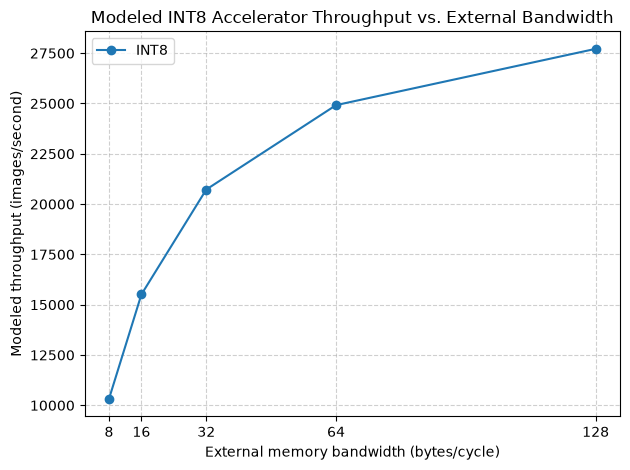

In [5]:
import matplotlib.pyplot as plt

bandwidth = [8, 16, 32, 64, 128]
int8_throughput = [10314.60, 15508.68, 20725.39, 24919.01, 27716.19]

fig, ax = plt.subplots()
ax.plot(bandwidth, int8_throughput, marker="o", label="INT8")
ax.set_title("Modeled INT8 Accelerator Throughput vs. External Bandwidth")
ax.set_xlabel("External memory bandwidth (bytes/cycle)")
ax.set_ylabel("Modeled throughput (images/second)")
ax.set_xticks(bandwidth)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend()
fig.tight_layout()
plt.show()

### Observation
At 32 lanes, increasing external memory bandwidth consistently improves INT8 modeled throughput. Throughput increases from approximately 10,315 images/s at 8 bytes/cycle to 27,716 images/s at 128 bytes/cycle.

This result supports the conclusion that memory bandwidth limits performance when the accelerator has a high degree of compute parallelism. Increasing compute resources alone is therefore not sufficient; sufficient memory bandwidth is also required to keep the processing lanes supplied with data.